# Cross validation and grid search

## What will you learn in this course? 🧐🧐

This course will teach you about a model evaluation technique called cross-validation, it will be very useful to get a more precise idea of how well your model performs on unknown data. It will also help you pick the best possible hyper-parameters for your model (e.g. the regularization strength)

* How to protect yourself from overfitting
* Diagnosing under/over-fitting
* Hyperparameter optimization
     * Example : tuning the regularization strength
     * Cross-validated grid search
     * Remark about computation time
         * Example 1 : tuning one hyperparameter
         * Example 2 : tuning several hyperparameters at the same time

## How to protect yourself from overfitting ⛔️

Under-fitting situations occur in practice, due to a lack of relevant data or can usualy be solved by using a more complex model. The most common enemy of data scientists however, is overfitting, because it gives the illusion of performance, but is actually a trap!

A simple and effective way to avoid this trap is to practice k-fold cross validation (other types of cross-validation techniques exist but we will use this one throughout this course). It is a process that consists in choosing an integer k (often 3 or 10 is chosen by default depending on the librairy used), and randomly splitting the observations into k groups of equal size. Then the following method is repeated k times:

* We isolate one group i among the k groups, which we call **validation set**, and we gather the 9 others, which we call **training set**.
* Estimate the chosen model using the **training set**.
* We calculate the error committed by model i on the **validation set** (group i).

The comparison of the train error and the validation error allows us to understand the real explanatory power of a model, because it quantifies the performance of the model on different sets of unknown data compared to its performance on known data.

As opposed to training the model on the train set and evaluate it using the test set, which only allows us to test the model's performance in one specific arrangement of the data, we now are able to measure the model's performance in a collection of randomly generated contexts using the data and figuring out how it performs on average. Cross validation gives information on how the model performs, and how stable or unstable its performance is depending on the data distribution.

overfitting


The figure above illustrates the principle of k-fold cross-validation. Each iteration produces results in terms of validation error and training error that are used to evaluate the model. These errors are usually calculated based on the cost function chosen to optimize the model, or simply on the average of the errors squared.

## Diagnosing under/over-fitting 🩺🩺
To detect underfitting or overfitting, the train/test (or train/validation) scores can be compared to each other :
* If $score(train) \sim score(test) \sim 0$ : the model is underfitting
* If $score(train) >> score(test)$ : the model is overfitting
* If $score(train) \sim score(test) >> 0$ : the model is just right !

> 👋 $>>$ means *lot more than*

## Hyperparameter optimization 🔧🔧

In machine learning, hyperparameter optimization or tuning is the problem of choosing a set of optimal hyperparameters for a learning algorithm. 

A hyperparameter is a parameter whose value is used to control the learning process, but is not directly used to compute the model's function. Hyperparameters are not tuned at the learning step, they have to be determined beforehand.  By contrast, the values of other parameters (typically, the coefficients of the model's function) are learned at the training step.

### Example : tuning the regularization strength
An example of model hyperparameter is the regularization strength (noted either $\lambda$ or $\alpha$, depending on the convention) in regularized linear regression models. The value of $\alpha$ has to be tuned to find the right model complexity and get performances that are "just right" between underfitting and overfitting.

### Cross-validated grid search
The traditional way of performing hyperparameter optimization is grid search, which is simply an exhaustive searching through a manually specified subset of the hyperparameter space of a learning algorithm. A grid search algorithm must be guided by some performance metric, typically measured by cross-validation on the training set.

The cross-validated grid search algorithm can be described by the following steps :
* Determine the list of values of the hyperparameters to be tested (for example : $\alpha = [0.1, 0.5, 1.0]$)
* For each combination of hyperparameters, perform k-fold CV to estimate the generalized score achieved with each hyperparameters values
* Pick the set of hyperparameters that define the model with the highest cross-validated score
* Re-train the model with this set of hyperparameters, on the whole training set

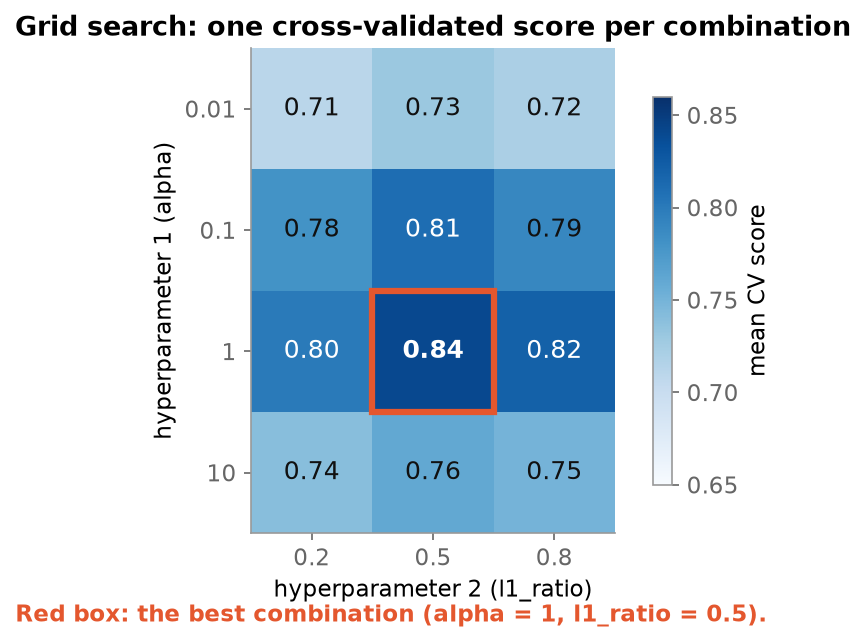

### Remark about computation time
Cross-validated grid search can be very time-consuming because the model training is repeated a high number of times ! Actually, for k-fold cross-validation, the number of model trainings n can be expressed as :

$$
n = k \times n_{comb}
$$

where $n_{comb}$ is the total number of combinations of hyperparameters values to be tested.

#### Example 1 : tuning one hyperparameter
Let's imagine we want to tune the regularization strength $\alpha$ and test 3 different values : $\alpha = [0.1, 0.5, 1.0]$. We would like to use 5-fold cross-validation.

Then, the total number of trainings in the cross-validated grid search will be :

$$
n = 5 \times 3 = 15
$$

#### Example 2 : tuning several hyperparameters at the same time
It is very common that we actually tune several hyperparameters at the same time. Let's imagine we want to tune three hyperparameters (respectively named $\alpha$, $\beta$ and $\gamma$) and we want to try the following values:
* $\alpha = [0.1, 0.5, 1.0]$ 
* $\beta = [1, 2, 3, 4]$
* $\gamma = [-1, 1]$

The numbers of values to be tested for each hyperparameter are respectively :
* $n_\alpha = 3$
* $n_\beta = 4$
* $n_\gamma = 2$

Then, the total number of combinations to be tested is :

$$
n_{comb} = 3 \times 4 \times 2 = 24
$$

If we want to perform 5-fold cross-validation, the total number of trainings in the cross-validated grid search will be :

$$
n = 5 \times 24 = 120
$$

## Resources 📚📚

* [Cross Validation: evaluating estimator performance](https://scikit-learn.org/stable/modules/cross_validation.html)

* [Kfold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html#sklearn.model_selection.KFold)

* [Exhaustive Grid Search](https://scikit-learn.org/stable/modules/grid_search.html#exhaustive-grid-search)